In [2]:



!pip install numpy scikit-learn joblib

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [40]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/dataset.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['dataset']


In [14]:
import os

DATASET_PATH = "/content/dataset/dataset"

classes = ["jpg", "pdf", "png", "txt", "gif"]

for label in classes:
    folder = os.path.join(DATASET_PATH, label)

    if os.path.isdir(folder):
        count = sum(
            os.path.isfile(os.path.join(folder, name))
            for name in os.listdir(folder)
        )
        print(f"{label.upper()}: {count} files")
    else:
        print(f"{label.upper()}: Folder not found")

JPG: 101 files
PDF: 101 files
PNG: 101 files
TXT: 101 files
GIF: 101 files


In [17]:

import os
import numpy as np

X = []
y = []

DATASET_PATH = "/content/dataset/dataset"

classes = ["jpg", "pdf", "png", "txt", "gif"]

for label in classes:
    folder = os.path.join(DATASET_PATH, label)

    if not os.path.isdir(folder):
        print(f"Folder not found: {folder}")
        continue

    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        if os.path.isfile(path):
            with open(path, "rb") as f:
                data = f.read()

            if len(data) == 0:
                continue

            features = np.bincount(
                np.frombuffer(data, dtype=np.uint8),
                minlength=256
            )

            features = features / len(data)

            X.append(features)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("Dataset loaded:", len(X))
print("Feature shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))



Dataset loaded: 505
Feature shape: (505, 256)
Labels: (array(['gif', 'jpg', 'pdf', 'png', 'txt'], dtype='<U3'), array([101, 101, 101, 101, 101]))


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import joblib

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))

joblib.dump(model, "/content/file_classifier.pkl")
print("Model saved!")

Accuracy: 0.8910891089108911
Model saved!


Classification Report:

              precision    recall  f1-score   support

         jpg       0.85      0.85      0.85        20
         pdf       0.79      0.95      0.86        20
         png       1.00      0.80      0.89        20
         txt       0.90      0.86      0.88        21
         gif       0.95      1.00      0.98        20

    accuracy                           0.89       101
   macro avg       0.90      0.89      0.89       101
weighted avg       0.90      0.89      0.89       101



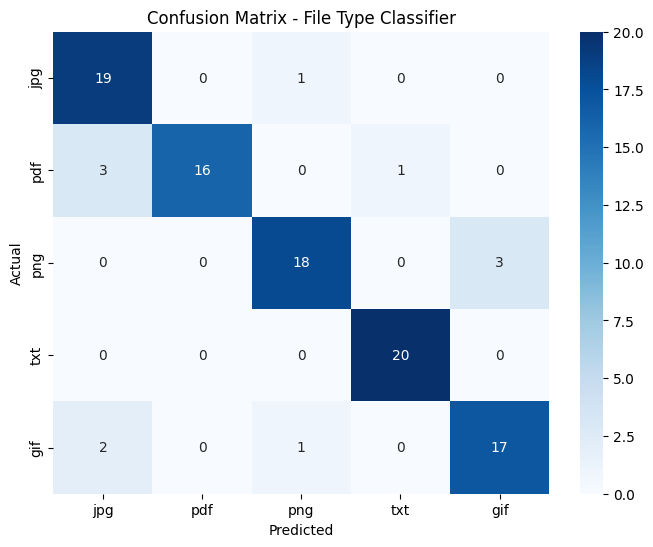

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Generate predictions for the test set
test_predictions = model.predict(X_test)

# Print detailed classification metrics
print("Classification Report:\n")
print(classification_report(y_test, test_predictions, target_names=classes))

# Calculate the confusion matrix
cm = confusion_matrix(y_test, test_predictions, labels=classes)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix - File Type Classifier")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [20]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-10-29 194111.png to Screenshot 2026-10-29 194111.png


In [21]:
model = joblib.load("/content/file_classifier.pkl")

In [35]:
import numpy as np

for filename, data in uploaded.items():

    if len(data) == 0:
        print("Empty file:", filename)
        continue

    features = np.bincount(
        np.frombuffer(data, dtype=np.uint8),
        minlength=256
    ).astype(float)

    features = features / len(data)

    prediction = model.predict([features])[0]

    print("Filename:", filename)
    print("Predicted file type:", prediction.upper())

Filename: Screenshot 2026-04-01 105252.png
Predicted file type: PNG


In [36]:
from google.colab import files

files.download("/content/file_classifier.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>